# Quickstart: NOAA RTMA analysis, virtual - dynamical.org Icechunk Zarr

NOAA's Real-Time Mesoscale Analysis (RTMA) combines observations with a model background to estimate near-surface weather each hour. This archive covers CONUS on the 2.5 km Western Expansion grid from 2 May 2017 onward, with temperature, moisture, wind, and cloud fields. These are gridded analyses, rather than individual station observations.

This dataset is currently available in the **staging catalog**. The open cell below selects staging; remove that override when the dataset is promoted to production.

Dataset documentation: https://rtma-analysis-staging.dynamical-org.pages.dev/catalog/noaa-rtma-analysis-virtual/

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install dynamical-catalog cartopy rioxarray pyproj matplotlib

In [2]:
import os

# RTMA is in staging; remove this override when it is promoted to production.
os.environ["DYNAMICAL_STAC_CATALOG_URL"] = (
    "https://stac-staging.dynamical.org/catalog.json"
)

import dynamical_catalog

ds = dynamical_catalog.open("noaa-rtma-analysis-virtual", chunks=None)
ds

<xarray.Dataset> Size: 32TB
Dimensions:                       (time: 83018, y: 1597, x: 2345)
Coordinates:
  * time                          (time) datetime64[ns] 664kB 2017-05-02 ... ...
  * y                             (y) float64 13kB 3.79e+06 ... -2.638e+05
  * x                             (x) float64 19kB -3.271e+06 ... 2.682e+06
    latitude                      (y, x) float32 15MB ...
    longitude                     (y, x) float32 15MB ...
    spatial_ref                   int64 8B ...
Data variables: (12/13)
    dew_point_temperature_2m      (time, y, x) float64 2TB ...
    cloud_ceiling_height          (time, y, x) float64 2TB ...
    geopotential_height_surface   (time, y, x) float64 2TB ...
    pressure_surface              (time, y, x) float64 2TB ...
    specific_humidity_2m          (time, y, x) float64 2TB ...
    temperature_2m                (time, y, x) float64 2TB ...
    ...                            ...
    wind_direction_10m            (time, y, x) float64 2TB ...
    wind_gust_10m                 (time, y, x) float64 2TB ...
    visibility_surface            (time, y, x) float64 2TB ...
    wind_v_10m                    (time, y, x) float64 2TB ...
    wind_speed_10m                (time, y, x) float64 2TB ...
    wind_u_10m                    (time, y, x) float64 2TB ...
Attributes:
    dataset_id:          noaa-rtma-analysis-virtual
    dataset_version:     0.1.0
    name:                NOAA RTMA analysis, virtual
    description:         Hourly Real-Time Mesoscale Analysis (RTMA) operated ...
    attribution:         NOAA NWS NCEP RTMA data processed by dynamical.org f...
    license:             CC-BY-4.0
    spatial_domain:      Continental United States
    spatial_resolution:  2.5 km
    time_domain:         2017-05-02 00:00:00 UTC to Present
    time_resolution:     1 hour

### How did the June 2021 heat wave evolve near Seattle?

The Pacific Northwest experienced [record heat in late June 2021](https://www.ncei.noaa.gov/news/national-climate-202106). Start with an hourly temperature series at the grid cell nearest Seattle; all times here are UTC.

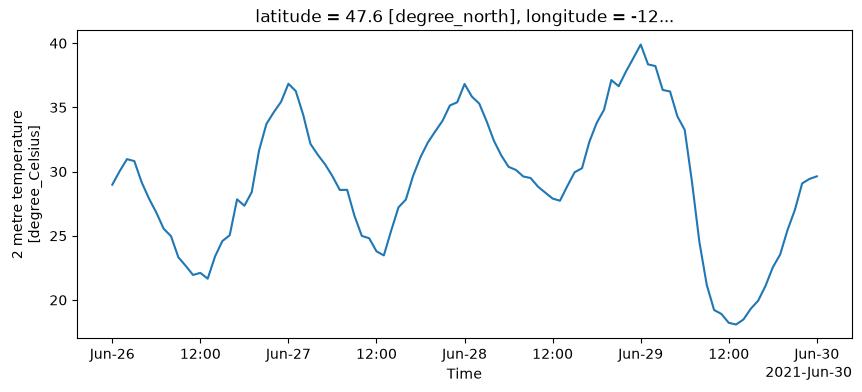

In [3]:
import rioxarray  # noqa: F401  enables the .rio accessor
from pyproj import Transformer

lon_lat_to_grid = Transformer.from_crs("EPSG:4326", ds.rio.crs, always_xy=True)
seattle_x, seattle_y = lon_lat_to_grid.transform(-122.33, 47.61)

(
    ds["temperature_2m"]
    .sel(time=slice("2021-06-26T00", "2021-06-30T00"))
    .sel(x=seattle_x, y=seattle_y, method="nearest")
    .plot(figsize=(10, 4))
)

Compare the point series with a regional temperature map at 23 UTC on 28 June (4 pm Pacific daylight time). The native grid is projected, so use its CRS both to select the region and to draw the map.

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from cartopy.mpl.geoaxes import GeoAxes

grid = ds.spatial_ref.attrs
rtma_proj = ccrs.LambertConformal(
    central_longitude=grid["longitude_of_central_meridian"],
    central_latitude=grid["latitude_of_projection_origin"],
    standard_parallels=grid["standard_parallel"],
    globe=ccrs.Globe(
        semimajor_axis=grid["semi_major_axis"],
        semiminor_axis=grid["semi_minor_axis"],
    ),
)


def borders(ax: GeoAxes) -> None:
    ax.add_feature(cfeature.STATES, edgecolor="0.35", linewidth=0.4)
    ax.coastlines(resolution="50m", linewidth=0.5, color="0.25")

/tmp/reform-rtma-notebooks/.venv/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


/tmp/reform-rtma-notebooks/.venv/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


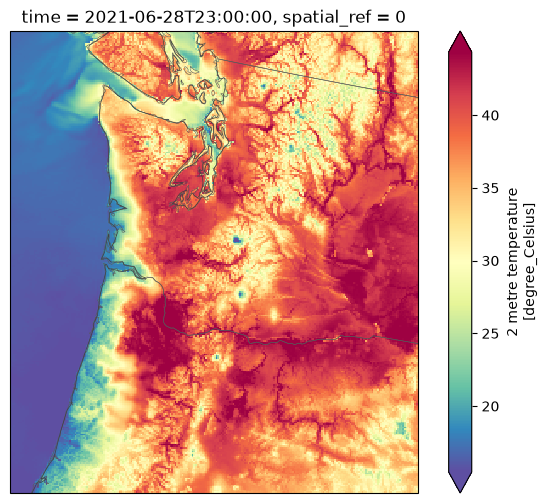

In [5]:
heat = (
    ds["temperature_2m"]
    .sel(time="2021-06-28T23")
    .rio.clip_box(-125, 44, -119, 49, crs="EPSG:4326")
)

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": rtma_proj})
heat.plot(ax=ax, transform=rtma_proj, cmap="Spectral_r", center=False, robust=True)
borders(ax)

### Where were strong winds and dry air during the Marshall Fire?

On 30 December 2021, [strong downslope winds along Colorado's Front Range fanned the Marshall Fire](https://www.weather.gov/bou/HighWinds12_30_2021). Compare analyzed 10 m wind speed with the temperature–dewpoint spread at 19 UTC (noon Mountain standard time); a larger spread indicates drier near-surface air, but does not measure fuel dryness or fire extent.

`wind_u_10m` and `wind_v_10m` are **grid-relative** components, so they require rotation before interpreting them as eastward/northward winds. Here we use the stored scalar wind speed; `wind_direction_10m` gives the direction from which wind blows, clockwise from true north.

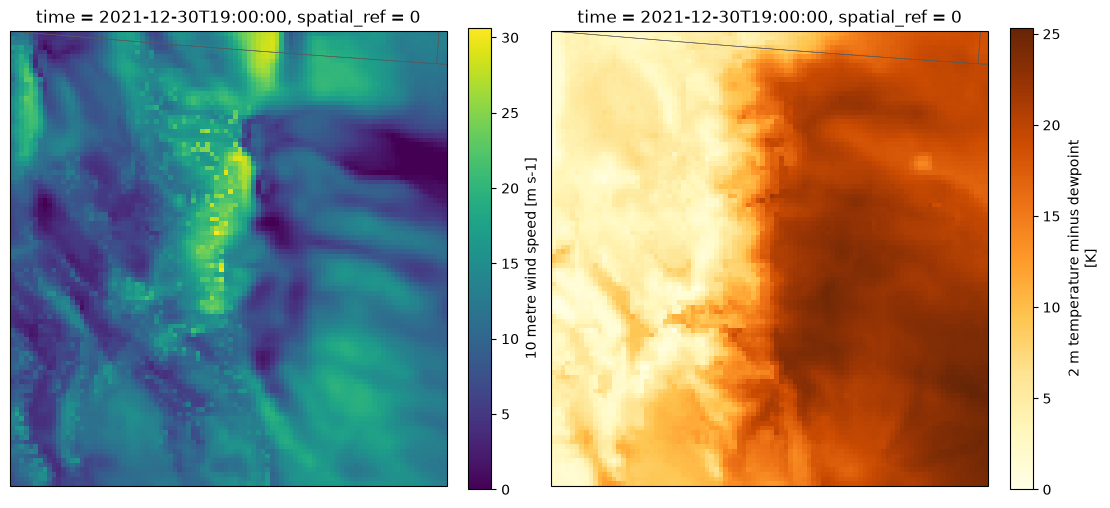

In [6]:
front_range = (
    ds[["wind_speed_10m", "temperature_2m", "dew_point_temperature_2m"]]
    .sel(time="2021-12-30T19")
    .rio.clip_box(-106.5, 39, -104, 41, crs="EPSG:4326")
    .load()
)
dewpoint_spread = front_range.temperature_2m - front_range.dew_point_temperature_2m
dewpoint_spread.attrs = {"long_name": "2 m temperature minus dewpoint", "units": "K"}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 5),
    subplot_kw={"projection": rtma_proj},
    constrained_layout=True,
)
front_range.wind_speed_10m.plot(ax=axes[0], transform=rtma_proj, cmap="viridis", vmin=0)
dewpoint_spread.plot(ax=axes[1], transform=rtma_proj, cmap="YlOrBr", vmin=0)
for ax in axes:
    borders(ax)

### Animated: how did cold air spread across Texas in February 2021?

An [Arctic outbreak brought cold air and winter weather to Texas in February 2021](https://www.weather.gov/fwd/Feb-2021-WinterEvent). Follow analyzed temperature from 14 February at 12 UTC to 15 February at 12 UTC, sampling every two hours and averaging 4 × 4 grid cells to keep the animation compact; the color scale stays fixed.

In [7]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

cold = (
    ds["temperature_2m"]
    .sel(time=slice("2021-02-14T12", "2021-02-15T12"))
    .isel(time=slice(None, None, 2))
    .rio.clip_box(-104, 26, -93, 36.5, crs="EPSG:4326")
    .coarsen(x=4, y=4, boundary="trim")
    .mean(keep_attrs=True)
    .load()
)

fig, ax = plt.subplots(
    figsize=(8, 6),
    dpi=72,
    subplot_kw={"projection": rtma_proj},
    constrained_layout=True,
)
image = cold.isel(time=0).plot(
    ax=ax,
    transform=rtma_proj,
    cmap="RdBu_r",
    vmin=-20,
    vmax=20,
)
borders(ax)


def draw_frame(i: int) -> None:
    image.set_array(cold.isel(time=i).values.ravel())
    ax.set_title(str(cold.time.values[i])[:16] + " UTC")


anim = FuncAnimation(fig, draw_frame, frames=cold.sizes["time"], interval=450)
plt.close(fig)
HTML(anim.to_jshtml())

### Before using ceiling and visibility

`cloud_ceiling_height` (source CEIL) and `visibility_surface` (VIS) retain raw finite source values in metres, including 1 and 9999: do not automatically replace them with missing values. Source bounds have changed over time, and an upper ceiling bound can also represent no-ceiling conditions. The archive does not assign a ceiling datum across its full history; consult the [validation report](https://dataset-validation-reports.dynamical.org/noaa-rtma-analysis-virtual/latest/validation_report.html) before interpreting ceiling heights, threshold counts, or trends. It also lists source archive gaps that appear as missing analyses.

### Community challenge

- How does the timing of the June heat-wave peak differ between coastal and inland grid cells, and how well does the analysis agree with independent stations?
- How well do HRRR near-surface temperature forecasts match RTMA at the same valid times during the Texas cold outbreak, and where are the largest differences?
- How does the Front Range wind-speed pattern vary between downslope wind events, and which terrain features recur in the strongest analyzed winds?